# GPT-2 124M · 단일 GPU
기존 프로젝트의 모델 및 학습 루프를 사용한다. GPT-2 124M을 무작위 초기화하고 문맥 길이 1,024를 사용한다.
한 번에 시퀀스 2개를 처리하고 4번 누적한다. 총 1,000스텝, 약 819만 토큰의 짧은 실험이다.
FineWeb-Edu `sample-10BT`에서 문서가 겹치지 않는 작은 검증·학습 구간만 읽는다.
학습 진행은 10스텝, 검증과 체크포인트는 100스텝마다 표시한다.


### 1. 실행 환경 확인
GPU 연결을 확인하고 데이터 준비와 학습에 필요한 패키지를 설치한다.

In [ ]:
from pathlib import Path
import subprocess
import sys
import torch

assert torch.cuda.is_available(), '런타임 유형에서 GPU를 선택하세요.'
print(torch.cuda.get_device_name(0), flush=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'datasets', 'tiktoken'], check=True)
work = Path('/content/gpt2_single_gpu')
work.mkdir(exist_ok=True)


Tesla T4


### 2. 모델과 실행 파일 준비
GPT-2 모델 코드와 단일 GPU용 학습 스크립트를 Colab 작업 폴더에 작성한다.

In [ ]:
(work / 'train_gpt2.py').write_text('import math\nimport inspect\nfrom dataclasses import dataclass\n\nimport numpy as np\nimport torch\nimport torch.nn as nn\nfrom torch.nn import functional as F\n\nclass CausalSelfAttention(nn.Module): # self attention layer 블럭\n    def __init__(self, config):\n        super().__init__()\n        assert config.n_embd % config.n_head == 0\n        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd) # 입력 토큰의 차원을 768 -> 2304차원으로 늘리고 Q,K,V로 나눔\n        self.c_proj = nn.Linear(config.n_embd, config.n_embd) # 각 head의 결과를 합침\n        self.c_proj.NANOGPT_SCALE_INIT = 1\n        self.n_head = config.n_head\n        self.n_embd = config.n_embd\n        \n    def forward(self, x):\n        B, T, C = x.size() # batch size, sequence length, embedding dimension\n        qkv = self.c_attn(x)\n        q,k,v = qkv.split(self.n_embd, dim=2)\n        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1,2) # head 개수대로 q,k,v의 차원 나눔 \n        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1,2)\n        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1,2)\n        y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # pytorch의 함수로 attention 계산\n        y = y.transpose(1,2).contiguous().view(B,T,C)\n        y = self.c_proj(y)\n        return y\n\n\nclass MLP(nn.Module):\n    def __init__(self,config):\n        super().__init__()\n        self.c_fc = nn.Linear(config.n_embd, 4*config.n_embd) # 768 -> 3072\n        self.gelu = nn.GELU(approximate=\'tanh\') # GELU로 비선형성 추가\n        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd) # 3072 -> 768 원래 차원으로\n        self.c_proj.NANOGPT_SCALE_INIT = 1\n        \n    def forward(self,x):\n        x = self.c_fc(x)\n        x = self.gelu(x)\n        x = self.c_proj(x)\n        return x\n\n\nclass Block(nn.Module):\n    def __init__(self,config):\n        super().__init__()\n        self.ln_1 = nn.LayerNorm(config.n_embd) # pre-LN으로 먼저 Layernorm 적용\n        self.attn = CausalSelfAttention(config) # causal selfattention layer 통과\n        self.ln_2 = nn.LayerNorm(config.n_embd)  \n        self.mlp = MLP(config) # mlp layer 통과\n        \n    def forward(self, x):\n        x = x+self.attn(self.ln_1(x)) # residual\n        x = x+self.mlp(self.ln_2(x))\n        return x\n\n\n@dataclass\nclass GPTConfig: # 모델 크기 설정\n    block_size: int = 1024 # 최대 입력 길이\n    vocab_size: int = 50304 # 사용할 토큰 종류의 개수\n    n_layers: int = 12 # transformer decoder의 블록 개수\n    n_head: int = 12 # attention head의 개수\n    n_embd: int = 768 # 각 토큰 별 표현 차원\n\n\nclass GPT(nn.Module):\n    def __init__(self, config):\n        super().__init__()\n        self.config = config\n        \n        self.transformer = nn.ModuleDict(dict( # GPT-2의 구조 뼈대 같은 것.\n            wte = nn.Embedding(config.vocab_size, config.n_embd),   # token embedding 번호에 해당하는 768차원의 벡터를 가져옴\n            wpe = nn.Embedding(config.block_size, config.n_embd),   # positional embedding 번호에 해당하는 768차원의 벡터를 가져옴\n            h = nn.ModuleList([Block(config) for _ in range(config.n_layers)]), # dot 0, 1, 2, ...\n            ln_f = nn.LayerNorm(config.n_embd),\n        ))\n        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False) # 다음 생성할 토큰들의 점수\n        self.transformer.wte.weight = self.lm_head.weight # 가중치 공유\n        self.apply(self._init_weights) \n        \n    def _init_weights(self, module):\n        if isinstance(module, nn.Linear):\n            std = 0.02\n            if hasattr(module, \'NANOGPT_SCALE_INIT\'):\n                std *= (2 * self.config.n_layers) ** -0.5\n            torch.nn.init.normal_(module.weight, mean=0.0, std=std)\n            if module.bias is not None:\n                torch.nn.init.zeros_(module.bias)\n        elif isinstance(module, nn.Embedding):\n            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)\n            \n    def forward(self, idx, targets=None):\n        # 입력은 BxT 크기의 idx\n        B, T = idx.size()\n        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"\n        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)\n        pos_emb = self.transformer.wpe(pos)\n        tok_emb = self.transformer.wte(idx)\n        # token embedding + position embedding을 입력으로 사용\n        x = tok_emb + pos_emb\n        \n        for block in self.transformer.h:\n            x = block(x)\n        x = self.transformer.ln_f(x)\n        logits = self.lm_head(x) # logits = (B,T,vocab_size) 얻게되는 tensor\n        loss = None\n        if targets is not None:\n            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))\n        return logits, loss\n    \n    @classmethod\n    def from_pretrained(cls, model_type):\n        assert model_type in {\'gpt2\', \'gpt2-medium\', \'gpt2-large\', \'gpt2-xl\'}\n        from transformers import GPT2LMHeadModel\n        print("loading weights from pretrained gpt: %s" % model_type)\n        \n        config_args = {\n            \'gpt2\': dict(n_layers=12, n_head=12, n_embd=768),\n            \'gpt2-medium\': dict(n_layers=24, n_head=16, n_embd=1024),\n            \'gpt2-large\': dict(n_layers=36, n_head=20, n_embd=1280),\n            \'gpt2-xl\': dict(n_layers=48, n_head=25, n_embd=1600),\n        }[model_type]\n        config_args[\'vocab_size\'] = 50257\n        config_args[\'block_size\'] = 1024\n        config = GPTConfig(**config_args)\n        model = cls(config)\n        sd = model.state_dict()\n        sd_keys = sd.keys()\n        sd_keys = [k for k in sd_keys if not k.endswith(\'.attn.bias\')]\n        \n        model_hf = GPT2LMHeadModel.from_pretrained(model_type)\n        sd_hf = model_hf.state_dict()\n        \n        # tensorflow를 pytorch로 변경하기 위해 하드코딩\n        sd_keys_hf = sd_hf.keys()\n        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith(\'.attn.masked_bias\')]\n        sd_keys_hf = [k for k in sd_keys_hf if not k.endswith(\'.attn.bias\')]\n        transposed = [\'attn.c_attn.weight\', \'attn.c_proj.weight\', \'mlp.c_fc.weight\', \'mlp.c_proj.weight\']\n        assert len(sd_keys_hf) == len(sd_keys), f"mismatched keys: HF={len(sd_keys_hf)}, mine={len(sd_keys)}"\n        assert set(sd_keys_hf) == set(sd_keys), \'가중치 이름이 일치하지 않습니다.\'\n        for k in sd_keys_hf: # hugging face의 gpt-2 가중치 덮어씀\n            if any(k.endswith(w) for w in transposed):\n                assert sd_hf[k].shape[::-1] == sd[k].shape\n                with torch.no_grad():\n                    sd[k].copy_(sd_hf[k].t())\n            else:\n                assert sd_hf[k].shape == sd[k].shape\n                with torch.no_grad():\n                    sd[k].copy_(sd_hf[k])\n        return model\n    \n    def configure_optimizers(self, weight_decay, learning_rate, device_type, master_process=True):\n        param_dict = {pn: p for pn, p in self.named_parameters()}\n        param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}\n        \n        decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]\n        nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]\n        optim_groups = [\n            {\'params\': decay_params, \'weight_decay\': weight_decay},\n            {\'params\': nodecay_params, \'weight_decay\': 0.0}\n        ]\n        num_decay_params = sum(p.numel() for p in decay_params)\n        num_nodecay_params = sum(p.numel() for p in nodecay_params)\n        if master_process:\n            print(f"num decayed parameter tensors: {len(decay_params)}, with {num_decay_params:,} parameters")\n            print(f"num non-decayed parameter tensors: {len(nodecay_params)}, with{num_nodecay_params:,} parameters")\n        fused_available = \'fused\' in inspect.signature(torch.optim.AdamW).parameters\n        use_fused = fused_available and device_type == \'cuda\'\n        if master_process:\n            print(f"using fused AdamW: {use_fused}")\n        optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=use_fused)\n        return optimizer\n\ndef load_tokens(filename):\n    npt = np.load(filename)\n    npt = npt.astype(np.int32)\n    return torch.tensor(npt, dtype=torch.long)\n\n\nclass DataLoaderLite:\n    def __init__(self, B, T, *, tokens=None, shards=None):\n        self.B = B\n        self.T = T\n        self.shards = shards\n        self.initial_tokens = tokens\n        self.reset()\n\n    def reset(self):\n        self.current_shard = 0\n        self.current_position = 0\n        if self.shards is not None:\n            self.tokens = load_tokens(self.shards[self.current_shard])\n        else:\n            self.tokens = self.initial_tokens\n\n    def next_batch(self):\n        B, T = self.B, self.T\n        buf = self.tokens[self.current_position:self.current_position + B*T + 1]\n        x = buf[:-1].view(B, T)\n        y = buf[1:].view(B, T)\n        self.current_position += B*T\n\n        # 다음 배치를 만들 수 없으면 다음 shard 또는 처음으로 이동\n        if self.current_position + B*T + 1 > len(self.tokens):\n            if self.shards is not None:\n                self.current_shard = (self.current_shard + 1) % len(self.shards)\n                self.tokens = load_tokens(self.shards[self.current_shard])\n            self.current_position = 0\n        return x, y\n\n\ndef get_lr(step, schedule):\n    warmup = schedule[\'warmup_steps\']\n    if warmup and step < warmup:\n        return schedule[\'lr\'] * (step + 1) / warmup\n    ratio = min(1.0, max(0.0, (step - warmup) / (schedule[\'decay_steps\'] - warmup)))\n    return schedule[\'min_lr\'] + 0.5 * (1.0 + math.cos(math.pi * ratio)) * (schedule[\'lr\'] - schedule[\'min_lr\'])\n', encoding='utf-8')
(work / 'run_gpt2.py').write_text('import csv\nimport time\nfrom dataclasses import asdict\nfrom datetime import datetime\nfrom pathlib import Path\n\nimport tiktoken\nimport torch\nfrom torch.nn import functional as F\n\nfrom train_gpt2 import GPT, GPTConfig, DataLoaderLite, get_lr\n\n# 실험 설정은 여기에서 변경\nmode = \'train\'                 # \'train\' 또는 \'generate\'\ncheckpoint_path = None         # 생성할 때 저장한 model.pt 경로\ndata_dir = \'edu_fineweb10B\'    # fineweb.py가 만든 train/val shard 폴더\nB, T = 2, 1024\ntotal_batch_size = 8192       # 한 번 갱신할 때 처리하는 전체 토큰 수\nmax_steps = 1000              # 업데이트 시도당 8,192토큰\nmax_lr = 3e-4\nmin_lr = max_lr * 0.1\nwarmup_steps = 100\neval_interval = 100\neval_batches = 20\ncheckpoint_interval = 100\nprint_interval = 10\nweight_decay = 0.1\nuse_amp = True\nuse_compile = False\nmodel_config = GPTConfig()\nprompt = "Hello, I\'m a language model,"\nmax_new_tokens = 16\ntop_k = 50\n\ndef main():\n    base_dir = Path(__file__).resolve().parent\n    device = \'cuda\' if torch.cuda.is_available() else \'cpu\'\n    assert device == \'cuda\', \'Colab 런타임에서 GPU를 선택하세요.\'\n    amp_dtype = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16\n    print(f\'using device: {torch.cuda.get_device_name()}, AMP: {amp_dtype}\')\n    torch.manual_seed(1337)\n    if device == \'cuda\':\n        torch.cuda.manual_seed(1337)\n        torch.set_float32_matmul_precision(\'high\')\n\n    enc = tiktoken.get_encoding(\'gpt2\')\n    assert mode in (\'train\', \'generate\')\n    if mode == \'generate\':\n        if checkpoint_path is None:\n            raise ValueError(\'checkpoint_path에 저장한 model.pt 경로를 적어 주세요.\')\n        path = Path(checkpoint_path)\n        if not path.is_absolute():\n            path = base_dir / path\n        checkpoint = torch.load(path, map_location=\'cpu\', weights_only=False)\n        model = GPT(GPTConfig(**checkpoint[\'config\']))\n        model.load_state_dict(checkpoint[\'model\'])\n    else:\n        model = GPT(model_config)\n    model.to(device)\n    raw_model = model\n    if use_compile:\n        model = torch.compile(model)\n\n    if mode == \'train\':\n        assert B > 0 and T > 0 and max_steps > warmup_steps >= 0\n        assert total_batch_size > 0 and total_batch_size % (B * T) == 0\n        assert 0 < min_lr <= max_lr and eval_interval > 0 and eval_batches > 0\n        assert checkpoint_interval > 0 and checkpoint_interval % eval_interval == 0\n        grad_accum_steps = total_batch_size // (B * T)\n        print(f\'training: {max_steps:,} steps, {total_batch_size:,} tokens/step, \'\n              f\'{max_steps * total_batch_size:,} tokens total\')\n\n        # 1. 데이터 준비: 학습용과 검증용을 나눔\n        if data_dir is None:\n            text = (base_dir / \'input.txt\').read_text(encoding=\'utf-8-sig\')\n            split = int(len(text) * 0.9)\n            train_tokens = torch.tensor(enc.encode_ordinary(text[:split]), dtype=torch.long)\n            val_tokens = torch.tensor(enc.encode_ordinary(text[split:]), dtype=torch.long)\n            train_loader = DataLoaderLite(B, T, tokens=train_tokens)\n            val_loader = DataLoaderLite(B, T, tokens=val_tokens)\n            print(f\'train: {len(train_tokens)} tokens, val: {len(val_tokens)} tokens\')\n        else:\n            folder = Path(data_dir)\n            if not folder.is_absolute():\n                folder = base_dir / folder\n            train_shards = sorted(folder.glob(\'*train*.npy\'))\n            val_shards = sorted(folder.glob(\'*val*.npy\'))\n            if not train_shards or not val_shards:\n                raise FileNotFoundError(\'FineWeb의 train/val shard를 모두 준비해야 합니다.\')\n            print(f\'FineWeb: {folder}\')\n            print(f\'train: {len(train_shards)} shards, val: {len(val_shards)} shards\')\n            train_loader = DataLoaderLite(B, T, shards=train_shards)\n            val_loader = DataLoaderLite(B, T, shards=val_shards)\n\n        optimizer = raw_model.configure_optimizers(weight_decay, max_lr, device)\n        scaler = torch.amp.GradScaler(\'cuda\', init_scale=4096, enabled=use_amp and amp_dtype == torch.float16)\n        schedule = {\'lr\': max_lr, \'min_lr\': min_lr,\n                    \'warmup_steps\': warmup_steps, \'decay_steps\': max_steps}\n        log_dir = base_dir / \'runs\' / datetime.now().strftime(\'%Y%m%d_%H%M%S_%f\')\n        log_dir.mkdir(parents=True, exist_ok=False)\n        print(f\'output: {log_dir}\')\n\n        # 2. 학습\n        with (log_dir / \'loss.csv\').open(\'w\', newline=\'\', encoding=\'utf-8\') as file:\n            writer = csv.writer(file)\n            writer.writerow([\'step\', \'train_loss\', \'val_loss\', \'lr\', \'grad_norm\', \'seconds\', \'tokens_per_second\'])\n            for step in range(max_steps):\n                if device == \'cuda\':\n                    torch.cuda.synchronize()\n                t0 = time.perf_counter()\n                model.train()\n                optimizer.zero_grad()\n                loss_accum = 0.0\n\n                for micro_step in range(grad_accum_steps):\n                    x, y = train_loader.next_batch()\n                    x, y = x.to(device), y.to(device)\n                    with torch.autocast(device_type=device, dtype=amp_dtype, enabled=use_amp):\n                        logits, loss = model(x, y)\n                    if not torch.isfinite(loss).item():\n                        raise RuntimeError(f\'step {step}: loss가 NaN/Inf입니다.\')\n                    loss = loss / grad_accum_steps\n                    loss_accum += loss.detach().item()\n                    scaler.scale(loss).backward()\n\n                scaler.unscale_(optimizer)\n                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=not scaler.is_enabled())\n                lr = get_lr(step, schedule)\n                for param_group in optimizer.param_groups:\n                    param_group[\'lr\'] = lr\n                scaler.step(optimizer)\n                scaler.update()\n                if device == \'cuda\':\n                    torch.cuda.synchronize()\n                dt = time.perf_counter() - t0\n                if step == 0 or (step + 1) % print_interval == 0 or step + 1 == max_steps:\n                    print(f\'step {step + 1:4d} | loss {loss_accum:.4f} | lr {lr:.2e} | {dt:.3f}s | {total_batch_size / dt:.0f} tok/s\', flush=True)\n\n                # 3. 검증과 저장\n                val_loss = None\n                if (step + 1) % eval_interval == 0 or step == max_steps - 1:\n                    model.eval()\n                    val_loader.reset()\n                    val_loss = 0.0\n                    with torch.no_grad():\n                        for _ in range(eval_batches):\n                            x, y = val_loader.next_batch()\n                            with torch.autocast(device_type=device, dtype=amp_dtype, enabled=use_amp):\n                                _, loss = model(x.to(device), y.to(device))\n                            if not torch.isfinite(loss).item():\n                                raise RuntimeError(\'검증 loss가 NaN/Inf입니다.\')\n                            val_loss += loss.item() / eval_batches\n                    print(f\'validation loss: {val_loss:.4f}\')\n                    # 업데이트를 마친 step 수로 저장. 검증과 저장 간격은 따로 설정한다.\n                    if (step + 1) % checkpoint_interval == 0 or step == max_steps - 1:\n                        checkpoint = {\'model\': raw_model.state_dict(),\n                                      \'config\': asdict(raw_model.config),\n                                      \'step\': step + 1, \'val_loss\': val_loss,\n                                      \'tokens_seen\': (step + 1) * total_batch_size}\n                        path = log_dir / f\'model_{step + 1:05d}.pt\'\n                        torch.save(checkpoint, path)\n                        print(f\'saved: {path}\')\n                        if step == max_steps - 1:\n                            torch.save(checkpoint, log_dir / \'model.pt\')\n                writer.writerow([step + 1, loss_accum, val_loss, lr, norm.item(), dt, total_batch_size / dt])\n                file.flush()\n\n    # 4. 문장 생성: 마지막 위치에서 다음 토큰을 하나씩 선택\n    model.eval()\n    tokens = enc.encode(prompt) or [enc.eot_token]\n    x = torch.tensor([tokens], dtype=torch.long, device=device)\n    assert 0 < top_k <= enc.n_vocab and max_new_tokens >= 0\n    torch.manual_seed(42)\n    if device == \'cuda\':\n        torch.cuda.manual_seed(42)\n    with torch.no_grad():\n        for _ in range(max_new_tokens):\n            with torch.autocast(device_type=device, dtype=amp_dtype, enabled=use_amp):\n                logits, _ = model(x[:, -raw_model.config.block_size:])\n            logits = logits[:, -1, :enc.n_vocab].float()\n            probs = F.softmax(logits, dim=-1)\n            topk_probs, topk_indices = torch.topk(probs, top_k, dim=-1)\n            ix = torch.multinomial(topk_probs, 1)\n            xcol = torch.gather(topk_indices, -1, ix)\n            x = torch.cat((x, xcol), dim=1)\n    result = enc.decode(x[0].tolist())\n    print(result)\n    if mode == \'train\':\n        (log_dir / \'sample.txt\').write_text(result, encoding=\'utf-8\')\n\n\nif __name__ == \'__main__\':\n    main()\n', encoding='utf-8')


8904

### 3. FineWeb-Edu 토큰화
FineWeb-Edu 일부를 GPT-2 토크나이저로 변환해 학습용과 검증용으로 나눈다.

In [ ]:
from datasets import load_dataset
import numpy as np
import tiktoken

data = work / 'edu_fineweb10B'
data.mkdir(exist_ok=True)
train_path = data / 'fineweb_train_000001.npy'
val_path = data / 'fineweb_val_000000.npy'
train_count = 1000 * 8192 + 1
val_count = 20 * 2 * 1024 + 1
if not (train_path.exists() and val_path.exists()):
    print('Streaming a FineWeb-Edu subset and tokenizing it...', flush=True)
    documents = iter(load_dataset('HuggingFaceFW/fineweb-edu', 'sample-10BT', split='train', streaming=True))
    enc = tiktoken.get_encoding('gpt2')

    def take_tokens(count):
        tokens = np.empty(count, dtype=np.uint16)
        position = 0
        while position < count:
            doc = next(documents)
            ids = [enc.eot_token] + enc.encode_ordinary(doc['text'])
            length = min(len(ids), count - position)
            tokens[position:position + length] = ids[:length]
            position += length
        return tokens

    # Each split consumes separate documents from the stream.
    np.save(val_path, take_tokens(val_count))
    np.save(train_path, take_tokens(train_count))
assert len(np.load(train_path, mmap_mode='r')) == train_count
assert len(np.load(val_path, mmap_mode='r')) == val_count
print('FineWeb-Edu train/validation ready.', flush=True)


Streaming a FineWeb-Edu subset and tokenizing it...


README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

FineWeb-Edu train/validation ready.


### 4. 첫 1,000스텝 학습
무작위 초기화에서 시작해 문맥 길이 1,024로 학습하고 검증 loss와 모델을 저장한다.

In [ ]:
import os

command = [sys.executable, '-u', 'run_gpt2.py']
process = subprocess.Popen(command, cwd=work, env=dict(os.environ, PYTHONUNBUFFERED='1'),
                           stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
try:
    for line in process.stdout:
        print(line, end='', flush=True)
    if process.wait():
        raise subprocess.CalledProcessError(process.returncode, command)
finally:
    if process.poll() is None:
        process.terminate()


using device: Tesla T4, AMP: torch.float16
training: 1,000 steps, 8,192 tokens/step, 8,192,000 tokens total
FineWeb: /content/gpt2_single_gpu/edu_fineweb10B
train: 1 shards, val: 1 shards
num decayed parameter tensors: 50, with 124,354,560 parameters
num non-decayed parameter tensors: 98, with121,344 parameters
using fused AdamW: True
output: /content/gpt2_single_gpu/runs/20261105_063302_267079
step    1 | loss 10.9752 | lr 3.00e-06 | 1.455s | 5629 tok/s
step   10 | loss 9.6411 | lr 3.00e-05 | 0.490s | 16716 tok/s
step   20 | loss 9.2362 | lr 6.00e-05 | 0.489s | 16760 tok/s
step   30 | loss 8.8442 | lr 9.00e-05 | 0.496s | 16531 tok/s
step   40 | loss 8.1251 | lr 1.20e-04 | 0.498s | 16458 tok/s
step   50 | loss 7.5908 | lr 1.50e-04 | 0.500s | 16391 tok/s
step   60 | loss 7.5189 | lr 1.80e-04 | 0.510s | 16073 tok/s
step   70 | loss 7.4894 | lr 2.10e-04 | 0.509s | 16083 tok/s
step   80 | loss 7.4053 | lr 2.40e-04 | 0.506s | 16193 tok/s
step   90 | loss 7.4788 | lr 2.70e-04 | 0.507s | 1616

### 5. 추가 학습 데이터 준비
처음 학습한 토큰 구간을 건너뛰고, 이어 학습할 FineWeb-Edu 토큰을 저장한다.

In [ ]:
# 1,001~10,000스텝용 FineWeb 토큰 준비
from datasets import load_dataset
import numpy as np
import tiktoken

resume_data = work / 'fineweb_continue_10000'
resume_data.mkdir(exist_ok=True)
train_file = resume_data / 'fineweb_train_000001.npy'
val_file = resume_data / 'fineweb_val_000000.npy'
previous_tokens = 1000 * 8192
new_tokens = 9000 * 8192
val_count = 20 * 2 * 1024 + 1

if not (train_file.exists() and val_file.exists()):
    docs = iter(load_dataset('HuggingFaceFW/fineweb-edu', 'sample-10BT', split='train', streaming=True))
    enc = tiktoken.get_encoding('gpt2')

    def document_tokens():
        doc = next(docs)
        return [enc.eot_token] + enc.encode_ordinary(doc['text'])

    # 첫 실험과 같은 검증 구간과 문서 경계를 복원한다.
    validation = []
    while len(validation) < val_count:
        validation.extend(document_tokens())
    np.save(val_file, np.asarray(validation[:val_count], dtype=np.uint16))

    # 앞서 처리한 학습 토큰을 건너뛰고 다음 구간을 저장한다.
    skip = previous_tokens
    block = document_tokens()
    while skip >= len(block):
        skip -= len(block)
        block = document_tokens()
    block = block[skip:]
    train = np.empty(new_tokens + 1, dtype=np.uint16)
    cursor = 0
    next_report = 10_000_000
    while cursor < len(train):
        length = min(len(block), len(train) - cursor)
        train[cursor:cursor + length] = block[:length]
        cursor += length
        if cursor >= next_report:
            print(f'Prepared {cursor:,} / {new_tokens + 1:,} tokens', flush=True)
            next_report += 10_000_000
        if cursor < len(train):
            block = document_tokens()
    temporary = train_file.with_suffix('.partial')
    with temporary.open('wb') as f:
        np.save(f, train)
    temporary.replace(train_file)
assert len(np.load(train_file, mmap_mode='r')) == new_tokens + 1
assert len(np.load(val_file, mmap_mode='r')) == val_count
print(f'Next training interval ready: {new_tokens:,} tokens.')

README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

Prepared 10,001,019 / 73,728,001 tokens
Prepared 20,000,349 / 73,728,001 tokens
Prepared 30,000,690 / 73,728,001 tokens
Prepared 40,001,302 / 73,728,001 tokens
Prepared 50,002,691 / 73,728,001 tokens
Prepared 60,000,557 / 73,728,001 tokens
Prepared 70,006,080 / 73,728,001 tokens
Next training interval ready: 73,728,000 tokens.


### 6. 체크포인트에서 이어 학습
1,000스텝 가중치에서 시작한다. 이번 실험은 6,000스텝 체크포인트를 저장하고 종료했다.

In [ ]:
# 1,000스텝 모델에서 총 10,000스텝까지 이어 학습
import os
import shutil
import time
import hashlib
from zipfile import ZipFile

archive_name = 'GPT2_Single_GPU_1000_results.zip'
archive_size = 498061342
archive_sha256 = 'e12d2e25eae43cf779c4023804eb099a26f6f64639a92619417cffca3f6ce7c2'

def uploaded_archive(path):
    if not path.is_file() or path.stat().st_size != archive_size:
        return False
    try:
        with path.open('rb') as f:
            return hashlib.file_digest(f, 'sha256').hexdigest() == archive_sha256
    except OSError:
        return False
print(f'Waiting for {archive_name} in session storage (up to 15 minutes).', flush=True)
for _ in range(180):
    candidates = (p for folder in (Path('/content'), Path('/')) for p in folder.glob('GPT2_Single_GPU_1000_results*.zip'))
    archive = next((p for p in candidates if uploaded_archive(p)), None)
    if archive is not None:
        break
    time.sleep(5)
if archive is None:
    raise FileNotFoundError('1,000스텝 결과 ZIP을 세션 저장소에 올린 뒤 이 셀을 다시 실행하세요.')

start_model = work / 'start_model_01000.pt'
temporary_model = start_model.with_suffix('.partial')
with ZipFile(archive) as bundle, bundle.open('model_01000.pt') as source, temporary_model.open('wb') as destination:
    shutil.copyfileobj(source, destination)
temporary_model.replace(start_model)
print('Checkpoint upload verified.', flush=True)
with ZipFile(archive) as bundle:
    (work / 'loss_1_to_1000.csv').write_bytes(bundle.read('loss.csv'))

source = (work / 'run_gpt2.py').read_text(encoding='utf-8')
changes = {
    "data_dir = 'edu_fineweb10B'": "data_dir = 'fineweb_continue_10000'",
    'max_steps = 1000': 'max_steps = 9000',
    'max_lr = 3e-4': 'max_lr = 1e-4',
    'eval_interval = 100': 'eval_interval = 200',
    'checkpoint_interval = 100': 'checkpoint_interval = 1000',
    'print_interval = 10': 'print_interval = 100',
    '        model = GPT(model_config)': '''        previous = torch.load(base_dir / 'start_model_01000.pt', map_location='cpu', weights_only=True)
        assert previous['step'] == 1000 and previous['tokens_seen'] == 8192000
        model = GPT(GPTConfig(**previous['config']))
        model.load_state_dict(previous['model'])
        print(f"Continuing from step {previous['step']}, previous validation {previous['val_loss']:.4f}", flush=True)
        del previous''',
    'step {step + 1:4d}': 'step {1000 + step + 1:5d}',
    "'step': step + 1": "'step': 1000 + step + 1",
    "'tokens_seen': (step + 1) * total_batch_size": "'tokens_seen': (1000 + step + 1) * total_batch_size",
    'model_{step + 1:05d}.pt': 'model_{1000 + step + 1:05d}.pt',
    'writer.writerow([step + 1,': 'writer.writerow([1000 + step + 1,',
}
for old, new in changes.items():
    assert source.count(old) == 1, old
    source = source.replace(old, new)
compile(source, 'run_continue_10000.py', 'exec')
(work / 'run_continue_10000.py').write_text(source, encoding='utf-8')

# 기존 체크포인트에는 AdamW 상태가 없으므로 optimizer는 새로 시작한다.
command = [sys.executable, '-u', 'run_continue_10000.py']
process = subprocess.Popen(command, cwd=work, env=dict(os.environ, PYTHONUNBUFFERED='1'),
                           stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
try:
    for line in process.stdout:
        print(line, end='', flush=True)
    if process.wait():
        raise subprocess.CalledProcessError(process.returncode, command)
finally:
    if process.poll() is None:
        process.terminate()

Waiting for GPT2_Single_GPU_1000_results.zip in session storage (up to 15 minutes).
Checkpoint upload verified.
using device: Tesla T4, AMP: torch.float16
Continuing from step 1000, previous validation 6.2392
training: 9,000 steps, 8,192 tokens/step, 73,728,000 tokens total
FineWeb: /content/gpt2_single_gpu/fineweb_continue_10000
train: 1 shards, val: 1 shards
num decayed parameter tensors: 50, with 124,354,560 parameters
num non-decayed parameter tensors: 98, with121,344 parameters
using fused AdamW: True
output: /content/gpt2_single_gpu/runs/20261105_071845_801142
step  1001 | loss 7.3655 | lr 1.00e-06 | 1.353s | 6054 tok/s
step  1100 | loss 6.4767 | lr 1.00e-04 | 0.562s | 14574 tok/s
step  1200 | loss 6.0165 | lr 1.00e-04 | 0.667s | 12286 tok/s
validation loss: 6.2416
step  1300 | loss 6.2515 | lr 9.99e-05 | 0.657s | 12463 tok/s
step  1400 | loss 6.2355 | lr 9.97e-05 | 0.669s | 12249 tok/s
validation loss: 6.1699
step  1500 | loss 6.3271 | lr 9.96e-05 | 0.677s | 12101 tok/s
step  16

CalledProcessError: Command '['/usr/bin/python3', '-u', 'run_continue_10000.py']' died with <Signals.SIGTERM: 15>.

### 7. 학습 결과 시각화
1~6,000스텝의 로그에서 학습 loss, 100스텝 이동평균, 검증 loss를 그린다.

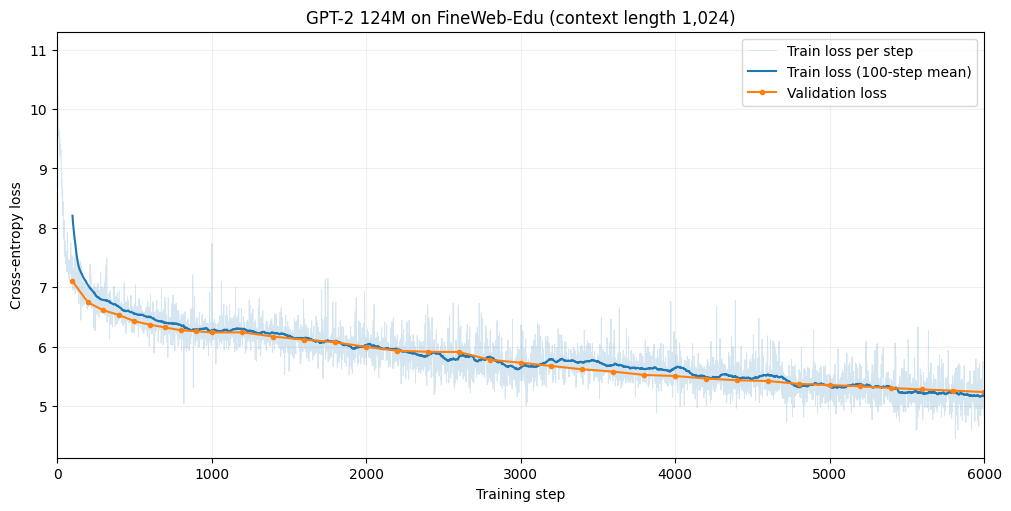

Final validation loss at step 6,000: 5.2366


In [8]:
# 1~6,000스텝의 학습 및 검증 loss 시각화
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

result_dir = Path('/content/gpt2_6000_results')
log_path = result_dir / 'loss_1_to_6000.csv'
if not log_path.is_file():
    log_path = Path('/content/loss_1_to_6000.csv')  # 새 런타임에는 CSV만 다시 업로드

with log_path.open(newline='', encoding='utf-8') as f:
    rows = list(csv.DictReader(f))

steps = np.array([int(row['step']) for row in rows])
train_loss = np.array([float(row['train_loss']) for row in rows])
validation = [row for row in rows if row['val_loss']]
val_steps = [int(row['step']) for row in validation]
val_loss = [float(row['val_loss']) for row in validation]

# 스텝별 변동과 전체 추세를 함께 볼 수 있도록 이동평균도 그린다.
window = 100
mean_loss = np.convolve(train_loss, np.ones(window) / window, mode='valid')
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
ax.plot(steps, train_loss, color='tab:blue', alpha=0.18, linewidth=0.7, label='Train loss per step')
ax.plot(steps[window - 1:], mean_loss, color='tab:blue', label='Train loss (100-step mean)')
ax.plot(val_steps, val_loss, 'o-', color='tab:orange', markersize=3, label='Validation loss')
ax.set(xlim=(0, steps[-1]), xlabel='Training step', ylabel='Cross-entropy loss',
       title='GPT-2 124M on FineWeb-Edu (context length 1,024)')
ax.grid(alpha=0.2)
ax.legend()
plt.show()
print(f'Final validation loss at step {val_steps[-1]:,}: {val_loss[-1]:.4f}')